# INCREMENT — лаборатория аплифта

Выполненный разбор: эксперимент → признаки → оценка на отдельном тесте → решение для бизнеса.

Для полной пересборки выполни из корня проекта: **python run.py**. Этот ноутбук читает результаты и независимо пересчитывает главный эффект. Поля данных и имена функций сохранены на английском для совместимости; подписи таблиц и пояснения — на русском.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
# Ноутбук запускается из корня проекта или из папки notebooks.
ROOT = Path.cwd()
if not (ROOT / 'run.py').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.localization import (
    ARM_LABELS, MODEL_LABELS, SPLIT_LABELS, STRATEGY_LABELS,
    FEATURE_LABELS, COLUMN_LABELS, table_for_display,
)
R = json.loads((ROOT / 'reports/results.json').read_text(encoding='utf-8'))
print('Клиентов:', R['quality']['rows'])
print('Разбиение:', {SPLIT_LABELS[k]: v for k, v in R['quality']['split_counts'].items()})
print('Версии библиотек:', R['versions'])

Клиентов: 64000
Разбиение: {'Обучение': 38400, 'Тест': 12800, 'Валидация': 12800}
Версии библиотек: {'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.5.2', 'scipy': '1.14.1', 'duckdb': '1.1.3', 'matplotlib': '3.9.2'}


## 1. Задача бизнеса
Кому отправить письмо с мужским или женским ассортиментом при ограниченном охвате? Основной исход — покупка за две недели. Главная проверка: персональный выбор письма против случайной рассылки мужского письма при охвате 20%.

In [2]:
metrics = pd.read_csv(ROOT/'reports/tables/experiment_metrics.csv')
print(table_for_display(metrics).to_string(index=False))

effects = pd.read_csv(ROOT/'reports/tables/experiment_effects.csv')
print('\nСредние эффекты на покупку:')
columns = ['arm', 'estimate', 'low', 'high', 'pvalue_holm']
print(table_for_display(effects.query("outcome == 'conversion'")[columns]).to_string(index=False))

        Группа  Клиентов  Покупок  Конверсия  Доля посещений  Выручка на клиента, $  Выручка, $
Мужское письмо     21307    267.0   0.012531        0.182757               1.422617    30311.69
    Без письма     21306    122.0   0.005726        0.106167               0.652789    13908.33
Женское письмо     21387    189.0   0.008837        0.151400               1.077202    23038.11

Средние эффекты на покупку:
        Письмо   Оценка  Нижняя граница 95% ДИ  Верхняя граница 95% ДИ  p с поправкой Холма
Мужское письмо 0.006805               0.005000                0.008610         5.884837e-13
Женское письмо 0.003111               0.001499                0.004724         3.116139e-04


## 2. Разделяем эксперимент и машинное обучение
Назначение писем случайное, вероятность каждой группы — 1/3. Разбиение 60/20/20 стратифицировано только по назначению. Модель выбирается на валидации; решения сохраняются до оценки теста. Совпадающие строки не удаляем: идентификатора клиента нет. source_row — лишь номер строки CSV.

In [3]:
splits = pd.read_csv(ROOT/'data/processed/splits.csv')
print(table_for_display(splits.groupby('split').source_row.agg(['count', 'nunique'])))
print('Номера строк уникальны между всеми выборками:', bool(splits.source_row.is_unique))
lock = R['selection']
decisions = {
    'Начальное значение генератора': lock['seed'],
    'Основной исход': 'Покупка за две недели',
    'Основной охват': lock['primary_coverage'],
    'Выбранные модели': {
        STRATEGY_LABELS[k]: MODEL_LABELS[v] for k, v in lock['selected_models'].items()
    },
    'Критерий выбора': lock['selection_metric'],
    'Главное сравнение': lock['primary_contrast'],
    'Вероятности назначения': lock['propensity'],
    'SHA-256 разбиения': lock['splits_sha256'],
}
print('Зафиксированные решения:')
print(json.dumps(decisions, ensure_ascii=False, indent=2))

           Строк  Уникальных строк
Выборка                           
Тест       12800             12800
Обучение   38400             38400
Валидация  12800             12800
Номера строк уникальны между всеми выборками: True
Зафиксированные решения:
{
  "Начальное значение генератора": 42,
  "Основной исход": "Покупка за две недели",
  "Основной охват": 0.2,
  "Выбранные модели": {
    "Аплифт / мужское письмо": "Логистическая регрессия, C=0,1",
    "Аплифт / выбор письма": "Логистическая регрессия, C=0,1"
  },
  "Критерий выбора": "Дополнительные покупки по AIPW на валидации при охвате 20%",
  "Главное сравнение": "Аплифт с выбором письма минус случайная рассылка мужского письма",
  "Вероятности назначения": [
    0.3333333333333333,
    0.3333333333333333,
    0.3333333333333333
  ],
  "SHA-256 разбиения": "411533ff17269ec30742a6bde4fbdd4eb4464381f45c0cc8db4842d100399c82"
}


## 3. Признаки и утечки
Используем только историю до воздействия. Пол клиента неизвестен: mens/womens означают прежние покупки соответствующего ассортимента. visit, conversion и spend измерены после письма и исключены из признаков модели.

In [4]:
from src.core import FEATURES
print('Признаки до рассылки:')
for feature in FEATURES:
    print(f'  {feature}: {FEATURE_LABELS[feature]}')
selection = pd.read_csv(ROOT/'reports/tables/model_selection.csv')
print('\nСравнение кандидатов на валидации:')
print(table_for_display(selection).to_string(index=False))

Признаки до рассылки:
  recency: Месяцев с прошлой покупки
  log_history: Логарифм прошлых расходов: log1p(history)
  mens: Прежние покупки мужского ассортимента
  womens: Прежние покупки женского ассортимента
  newbie: Новый клиент
  zip_code: Тип местности
  channel: Канал прошлых покупок

Сравнение кандидатов на валидации:
                        Модель               Стратегия  Охват    Оценка  Стандартная ошибка  Нижняя граница 95% ДИ  Верхняя граница 95% ДИ
Логистическая регрессия, C=0,1 Аплифт / мужское письмо    0.2  0.001228            0.001140              -0.001007                0.003462
Логистическая регрессия, C=0,1   Аплифт / выбор письма    0.2  0.000776            0.001042              -0.001266                0.002819
  Логистическая регрессия, C=1 Аплифт / мужское письмо    0.2  0.001228            0.001140              -0.001008                0.003463
  Логистическая регрессия, C=1   Аплифт / выбор письма    0.2 -0.000164            0.001043              -0.002208  

## 4. Модель покупки и аплифт
T-learner обучает отдельную модель вероятности покупки для каждой группы. Стратегия вероятности покупки ранжирует клиентов по прогнозу с мужским письмом; аплифт мужского письма — по разнице прогноза с письмом и без. Модели у этих двух стратегий одинаковые, отличается ранжирование. Стратегия выбора письма берёт вариант с наибольшим предсказанным приростом.

In [5]:
h = pd.read_csv(ROOT/'data/processed/holdout_predictions.csv')
columns = ['binary_p_0', 'binary_p_1', 'multi_p_0', 'multi_p_1', 'multi_p_2']
print(table_for_display(h[columns].head().round(5)).to_string(index=False))
uplift = h[['multi_p_1', 'multi_p_2']].to_numpy()-h[['multi_p_0']].to_numpy()
quantiles = np.quantile(uplift.max(axis=1), [0, .25, .5, .75, 1])
print('Квантили предсказанного прироста (0%, 25%, 50%, 75%, 100%):', quantiles)

 Без письма: модель мужского письма  Мужское письмо: модель мужского письма  Без письма: модель выбора письма  Мужское письмо: модель выбора письма  Женское письмо: модель выбора письма
                            0.00373                                 0.00925                           0.00373                               0.00925                               0.00391
                            0.00549                                 0.00961                           0.00549                               0.00961                               0.00794
                            0.00340                                 0.00641                           0.00340                               0.00641                               0.00789
                            0.00922                                 0.01279                           0.00922                               0.01279                               0.01500
                            0.00876                                 0.

## 5. Оценка стратегии через AIPW
Для каждого действия: score_a = mu_a(X) + I(A=a)/e_a × (Y−mu_a(X)).

Сравниваем ожидаемый исход стратегии с действием «без письма». Модель исходов mu обучена на объединении обучения и валидации. Известная вероятность воздействия позволяет корректировать ошибки модели исходов. Значения score не ограничиваем диапазоном [0,1].

In [6]:
from src.core import arm_scores, policy_weights, policy_scores, summarize
mu = h[['mu_0', 'mu_1', 'mu_2']].to_numpy()
phi = arm_scores(h.conversion.to_numpy(), h.action.to_numpy(), mu)
score = uplift.max(axis=1)
best_email = uplift.argmax(axis=1)+1
personal = policy_weights(score, .2, best_email)
random = policy_weights(np.zeros(len(h)), .2, 1, random=True)
personal_gain = policy_scores(personal, phi)-phi[:, 0]
random_gain = policy_scores(random, phi)-phi[:, 0]
comparison = summarize(personal_gain-random_gain, scale=10000)
print('Дополнительные покупки на 10 000: персонализация минус случайный выбор')
for key, value in comparison.items():
    print(f'{COLUMN_LABELS[key]}: {value:.4f}')
matches = np.isclose(comparison['estimate'], R['primary']['estimate']*10000)
print('Сохранённый результат воспроизведён:', bool(matches))

Дополнительные покупки на 10 000: персонализация минус случайный выбор
Оценка: -2.3303
Стандартная ошибка: 9.0174
Нижняя граница 95% ДИ: -20.0044
Верхняя граница 95% ДИ: 15.3439
Сохранённый результат воспроизведён: True


## 6. Что можно утверждать
Если интервал парной разницы содержит ноль, преимущество персонализации не установлено. Это не доказывает равенство стратегий. Отдельные интервалы стратегий не заменяют парное сравнение. Другие охваты на том же тесте — исследовательский анализ.

In [7]:
policies = pd.read_csv(ROOT/'reports/tables/test_policies.csv')
p20 = policies[np.isclose(policies.coverage, .2)].copy()
for column in ['estimate', 'low', 'high']:
    p20[column] *= 10000
print(table_for_display(p20[['label', 'estimate', 'low', 'high']]).to_string(index=False))

                Стратегия    Оценка  Нижняя граница 95% ДИ  Верхняя граница 95% ДИ
Случайно / мужское письмо 17.201485               8.545482               25.857487
      Вероятность покупки 17.336076              -7.996497               42.668649
         Недавние покупки 28.955131               2.852007               55.058255
  Аплифт / мужское письмо 17.499017              -1.854675               36.852709
    Аплифт / выбор письма 14.871221              -5.010299               34.752742


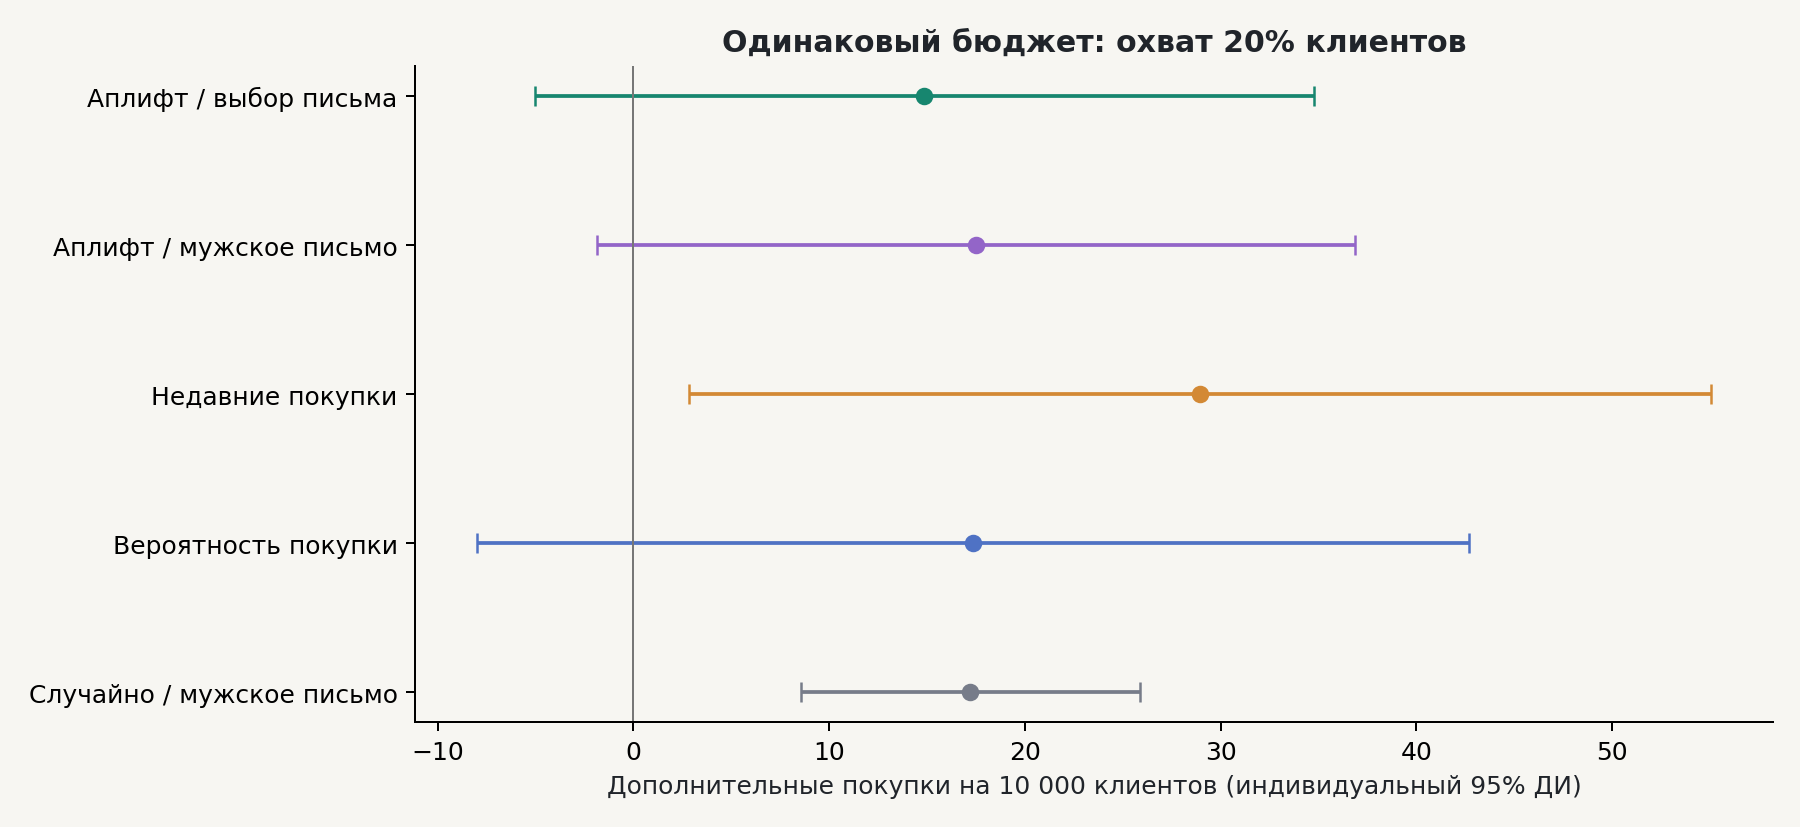

In [8]:
# График построен командой python run.py

## 7. Экономика сценария
Дополнительная прибыль = N × дополнительная вероятность покупки × маржа − N × охват × стоимость контакта. Маржа и стоимость — допущения сценария. Все суммы в долларах США; пересчёта в рубли нет. Интервалы условны на модели, не учитывают обучение и неопределённость переноса на новый бизнес.

In [9]:
N, margin, cost, coverage = 10000, 25, .02, .2
gain = summarize(personal_gain)
expense = N*coverage*cost
print('Контактов:', int(N*coverage), 'Расходы, $:', expense)
print('Сценарная дополнительная прибыль, $:', N*gain['estimate']*margin-expense)
print('Сценарный 95% ДИ, $:', (
    N*gain['low']*margin-expense, N*gain['high']*margin-expense,
))

Контактов: 2000 Расходы, $: 40.0
Сценарная дополнительная прибыль, $: 331.780530270031
Сценарный 95% ДИ, $: (-165.25748135353768, 828.8185418935998)


## 8. Следующий шаг бизнеса
Зафиксировать сегментацию и охват до новой кампании, затем провести новый рандомизированный тест стратегий. Для долгосрочного решения измерять покупки, маржу, отписки и повторные контакты. Ограничения — в reports/REPORT_RU.md; калькулятор — в reports/dashboard.html. Словарь исходных полей — в DATA_SOURCES.md; словарь выгружаемых таблиц — в reports/tables/README_RU.md.